# 10 - Reducción de dimensionalidad y perfiles territoriales

- Unidad de análisis: barrio (48 unidades).
- PCA resume relaciones lineales entre indicadores estandarizados; MCA explora asociaciones entre categorías.
- Las representaciones sirven para visualizar y preparar segmentaciones, no para construir un índice habitacional oficial.
- El PCA/MCA inicial se limita a servicios y transporte: no incluye precios ni alquileres, para que la segmentación posterior no dependa de las variables que el modelo explicativo estudiará.
- Las variables se eligen por cobertura y relevancia para las decisiones; precios con baja cobertura se describen aparte.
- Salidas: varianza, cargas y coordenadas en `data/processed/reports/`.

## 1. Preparación de variables

- Se parte del perfil territorial exportado por 09, construido con los KPIs de servicios y transporte por barrio.
- Se reportan faltantes antes de seleccionar variables; no se imputan variables con cobertura demasiado baja.
- Se aplica log(1+x) a densidades sesgadas seleccionadas y luego estandarización.
- La selección final de variables debe revisarse antes de interpretar componentes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from src import config

REPORTS = config.REPORTS_DIR
perfil = pd.read_csv(config.PROCESSED_DIR / "pe3_features_barrios_v1.csv")
candidatas = [c for c in perfil.columns if c != "barrio_oficial"]
faltantes = perfil[candidatas].isna().mean().sort_values(ascending=False)
display((100 * faltantes).round(1).rename("faltantes_pct").to_frame())

features = [c for c in candidatas if faltantes[c] <= .25]
assert len(features) >= 3, "No hay suficientes variables con cobertura adecuada."
x = perfil[features].replace([np.inf, -np.inf], np.nan).copy()
for col in features:
    if col.endswith("_km2"):
        x[col] = np.log1p(x[col].clip(lower=0))

imputador = SimpleImputer(strategy="median")
escalador = StandardScaler()
x_imp = imputador.fit_transform(x)
x_std = escalador.fit_transform(x_imp)
print("Barrios:", len(perfil), "| variables retenidas:", len(features))
print("Variables:", features)

,faltantes_pct
densidad_subte_km2,0.0
densidad_tren_km2,0.0
densidad_metrobus_km2,0.0
densidad_hospitales_km2,0.0
densidad_educacion_km2,0.0
densidad_culturales_km2,0.0
densidad_gastronomia_km2,0.0
densidad_espacios_verdes_km2,0.0
pct_superficie_verde,0.0


Barrios: 48 | variables retenidas: 9
Variables: ['densidad_subte_km2', 'densidad_tren_km2', 'densidad_metrobus_km2', 'densidad_hospitales_km2', 'densidad_educacion_km2', 'densidad_culturales_km2', 'densidad_gastronomia_km2', 'densidad_espacios_verdes_km2', 'pct_superficie_verde']


## 2. PCA: componentes y cargas

- Se presenta varianza explicada por componente y acumulada.
- Las cargas muestran qué variables contribuyen a cada eje.
- Se interpreta cada componente por sus variables con mayor carga absoluta, no por una etiqueta automática.

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.347,0.347
1,PC2,0.194,0.541
2,PC3,0.141,0.683
3,PC4,0.100,0.783
4,PC5,0.084,0.867
5,PC6,0.054,0.921
6,PC7,0.041,0.962
7,PC8,0.026,0.988
8,PC9,0.012,1.000


,PC1,PC2,PC3
densidad_subte_km2,0.449,-0.029,0.175
densidad_tren_km2,-0.046,-0.092,-0.548
densidad_metrobus_km2,0.283,0.205,-0.482
densidad_hospitales_km2,-0.003,-0.299,0.602
densidad_educacion_km2,0.315,-0.511,-0.129
densidad_culturales_km2,0.526,0.010,0.058
densidad_gastronomia_km2,0.511,0.160,0.107
densidad_espacios_verdes_km2,0.245,0.451,0.074
pct_superficie_verde,-0.143,0.607,0.191


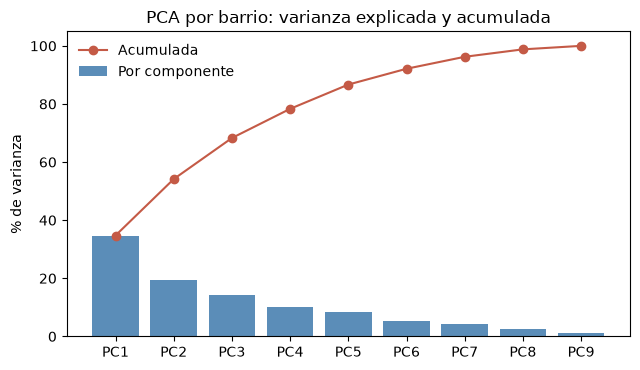

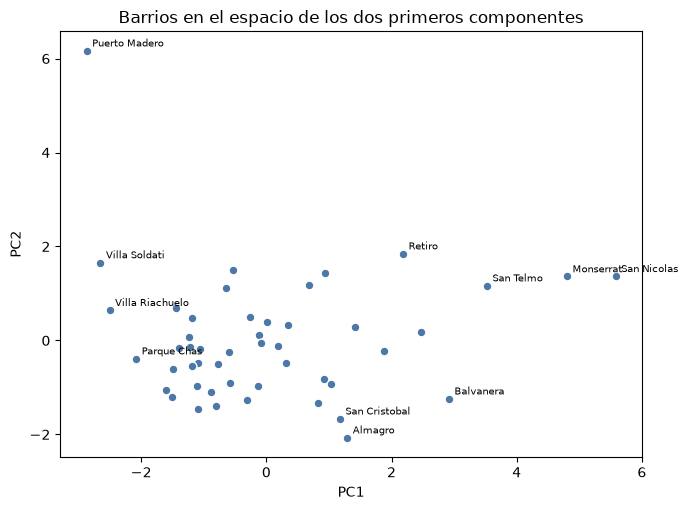

In [2]:
pca = PCA()
coord = pca.fit_transform(x_std)
nombres_pc = ["PC{}".format(i + 1) for i in range(coord.shape[1])]
varianza = pd.DataFrame({
    "componente": nombres_pc,
    "varianza_explicada": pca.explained_variance_ratio_,
    "varianza_acumulada": np.cumsum(pca.explained_variance_ratio_),
})
cargas = pd.DataFrame(pca.components_.T, index=features, columns=nombres_pc)
scores = pd.DataFrame(coord, columns=nombres_pc)
scores.insert(0, "barrio_oficial", perfil["barrio_oficial"])

display(varianza.round(3))
display(cargas.iloc[:, :min(3, len(cargas.columns))].round(3))
varianza.to_csv(REPORTS / "pe3_pca_varianza_v1.csv", index=False)
cargas.rename_axis("variable").to_csv(REPORTS / "pe3_pca_cargas_v1.csv")
scores.to_csv(config.PROCESSED_DIR / "pe3_pca_barrios_scores_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
barras = ax.bar(varianza["componente"], 100 * varianza["varianza_explicada"], color="#5b8db8")
linea, = ax.plot(varianza["componente"], 100 * varianza["varianza_acumulada"], color="#c45a46", marker="o")
ax.set_ylabel("% de varianza")
ax.set_title("PCA por barrio: varianza explicada y acumulada")
ax.legend([linea, barras], ["Acumulada", "Por componente"], frameon=False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(scores["PC1"], scores["PC2"], color="#4b78a8", s=40, edgecolor="white")
extremos = pd.concat([scores.nsmallest(4, "PC1"), scores.nlargest(4, "PC1"),
                      scores.nsmallest(2, "PC2"), scores.nlargest(2, "PC2")]).drop_duplicates("barrio_oficial")
for _, fila in extremos.iterrows():
    ax.annotate(fila["barrio_oficial"], (fila["PC1"], fila["PC2"]),
                xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Barrios en el espacio de los dos primeros componentes")
plt.tight_layout()
plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

## 3. MCA: categorías territoriales

- Se discretizan cuatro indicadores en terciles; se reducen automáticamente los cortes si hay empates.
- MCA se usa como contraste cualitativo de perfiles, no para recuperar magnitudes precisas.
- Las categorías se conservan visibles para explicar la posición de cada barrio.

,dimension,inercia_explicada
0,Dim1,0.233
1,Dim2,0.144


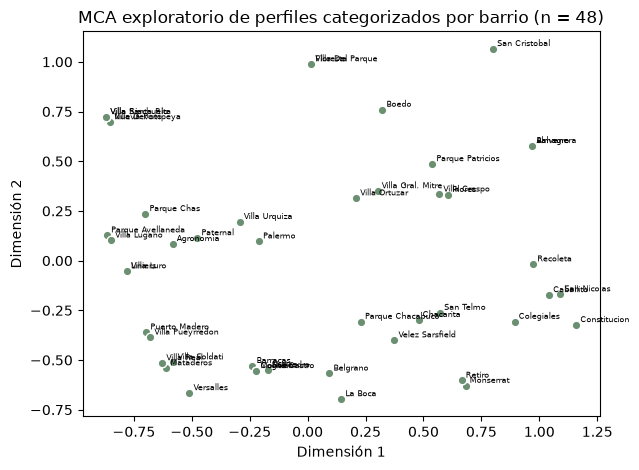

In [3]:
from scipy.linalg import svd

variables_mca = [
    "densidad_subte_km2", "densidad_metrobus_km2",
    "densidad_culturales_km2", "densidad_educacion_km2",
    "pct_superficie_verde",
]
variables_mca = [c for c in variables_mca if c in perfil.columns]
mca_cat = pd.DataFrame(index=perfil.index)
for col in variables_mca:
    s = perfil[col].replace([np.inf, -np.inf], np.nan)
    if s.notna().sum() < 30 or s.nunique(dropna=True) < 3:
        continue
    mca_cat[col + "_nivel"] = pd.qcut(s, q=3, duplicates="drop").astype(object)
mca_cat = mca_cat.dropna()
assert mca_cat.shape[1] >= 2 and len(mca_cat) >= 30, "No hay cobertura suficiente para MCA."
Z = pd.get_dummies(mca_cat, dtype=float).to_numpy()
P = Z / Z.sum()
masa_fila = P.sum(axis=1)
masa_col = P.sum(axis=0)
den = np.sqrt(np.outer(masa_fila, masa_col))
S = (P - np.outer(masa_fila, masa_col)) / den
U, valores_singulares, Vt = svd(S, full_matrices=False)
coord_mca = U[:, :2] * valores_singulares[:2] / np.sqrt(masa_fila[:, None])
inercia = valores_singulares ** 2
inercia_pct = inercia / inercia.sum()

mca_scores = pd.DataFrame(coord_mca, columns=["Dim1", "Dim2"], index=mca_cat.index)
mca_scores.insert(0, "barrio_oficial", perfil.loc[mca_scores.index, "barrio_oficial"])
display(pd.DataFrame({"dimension": ["Dim1", "Dim2"], "inercia_explicada": inercia_pct[:2]}).round(3))
mca_scores.to_csv(config.PROCESSED_DIR / "pe3_mca_barrios_scores_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.scatter(mca_scores["Dim1"], mca_scores["Dim2"], color="#6b8f71", s=38, edgecolor="white")
for _, fila in mca_scores.iterrows():
    ax.annotate(fila["barrio_oficial"], (fila["Dim1"], fila["Dim2"]),
                xytext=(3, 2), textcoords="offset points", fontsize=6)
ax.set_xlabel("Dimensión 1")
ax.set_ylabel("Dimensión 2")
ax.set_title("MCA exploratorio de perfiles categorizados por barrio (n = {})".format(len(mca_scores)))
plt.tight_layout()
plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

## 4. Criterios de interpretación

- Revisar si la varianza explicada se concentra en pocos componentes.
- Identificar variables con cargas altas y de signo opuesto.
- Comparar la configuración PCA/MCA con los KPIs originales y con los resultados de 08.
- Si los ejes dependen de pocos casos o cambian mucho al quitar una variable, reducir la interpretación.
- No traducir una proximidad en el gráfico a similitud causal ni a recomendación pública.

## Panel visual de síntesis: ejes y contribuciones
Las tarjetas indican cuánta información resume el plano y el gráfico de cargas muestra qué variables sostienen los primeros componentes. En PCA, el signo de cada eje es arbitrario; importan las magnitudes y los contrastes entre cargas. El plano de barrios es una proyección, no una clasificación oficial.

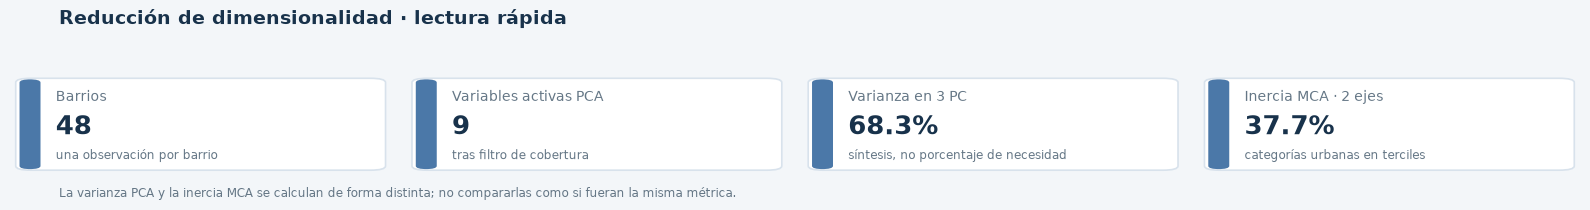

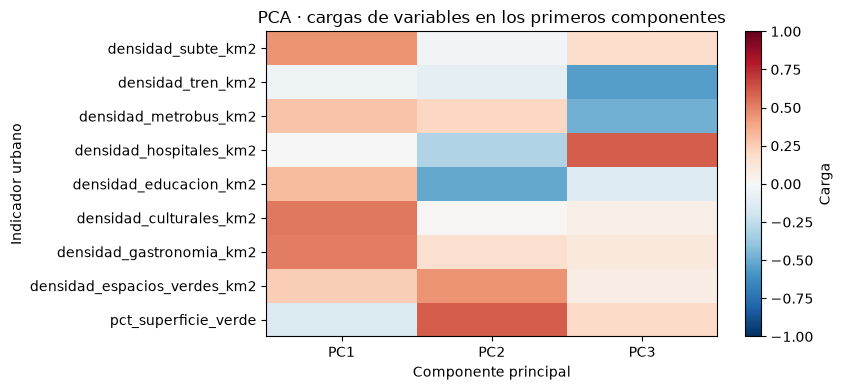

In [4]:
from src.pe3_visuals import kpi_cards
n_pc3 = min(3, len(varianza))
kpi_cards([
 ("Barrios", f"{len(perfil)}", "una observación por barrio"),
 ("Variables activas PCA", f"{len(features)}", "tras filtro de cobertura"),
 ("Varianza en 3 PC", f"{100*varianza['varianza_explicada'].iloc[:n_pc3].sum():.1f}%", "síntesis, no porcentaje de necesidad"),
 ("Inercia MCA · 2 ejes", f"{100*inercia_pct[:2].sum():.1f}%", "categorías urbanas en terciles"),
], title="Reducción de dimensionalidad · lectura rápida",
note="La varianza PCA y la inercia MCA se calculan de forma distinta; no compararlas como si fueran la misma métrica.")
L = cargas.iloc[:, :min(3, len(cargas.columns))]
fig, ax = plt.subplots(figsize=(8.5, max(4, .42*len(L))))
im = ax.imshow(L.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_yticks(np.arange(len(L))); ax.set_yticklabels(L.index)
ax.set_xticks(np.arange(L.shape[1])); ax.set_xticklabels(L.columns)
ax.set_title("PCA · cargas de variables en los primeros componentes")
ax.set_xlabel("Componente principal"); ax.set_ylabel("Indicador urbano")
fig.colorbar(im, ax=ax, label="Carga")
plt.tight_layout(); plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

**Lectura guiada.** Filas con cargas de magnitud alta caracterizan el componente; cargas de signos opuestos marcan un contraste. Una variable puede influir en más de un eje. Validar cualquier nombre asignado al componente contra las unidades originales y los KPIs territoriales.

,barrio_oficial,calidad_representacion_PC1_PC2
41,Villa Ortuzar,0.002
33,Velez Sarsfield,0.009
6,Boedo,0.020
8,Chacarita,0.026
3,Barracas,0.057
5,La Boca,0.065
19,Nuñez,0.072
24,Parque Patricios,0.116
22,Parque Chacabuco,0.191
0,Agronomia,0.201


Calidad de representación mediana: 0.425

Barrios menos representados en el plano PC1-PC2:


,barrio_oficial,calidad_representacion_PC1_PC2
41,Villa Ortuzar,0.002
33,Velez Sarsfield,0.009
6,Boedo,0.020
8,Chacarita,0.026
3,Barracas,0.057
5,La Boca,0.065
19,Nuñez,0.072
24,Parque Patricios,0.116
22,Parque Chacabuco,0.191
0,Agronomia,0.201


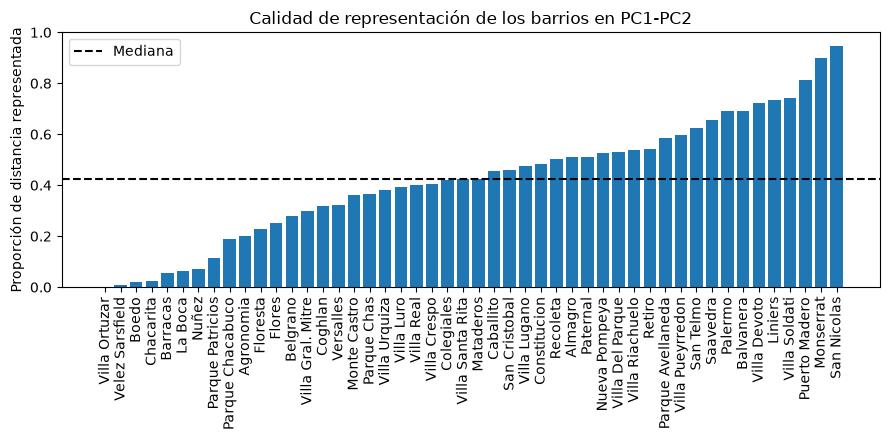

In [5]:
# Calidad de representación de los barrios en los primeros componentes

n_componentes = min(2, coord.shape[1])

# Coordenadas de los barrios en todos los componentes
coord_completa = pca.transform(x_std)

# Distancia cuadrática total al origen en el espacio estandarizado
distancia_total = np.sum(coord_completa ** 2, axis=1)

# Distancia cuadrática conservada en el plano de los primeros componentes
distancia_representada = np.sum(
    coord_completa[:, :n_componentes] ** 2, axis=1
)

calidad = np.divide(
    distancia_representada,
    distancia_total,
    out=np.zeros_like(distancia_representada),
    where=distancia_total > 0
)

calidad_barrios = pd.DataFrame({
    "barrio_oficial": perfil["barrio_oficial"],
    "calidad_representacion_PC1_PC2": calidad
})

calidad_barrios = calidad_barrios.sort_values(
    "calidad_representacion_PC1_PC2"
)

display(calidad_barrios.round(3))

print(
    "Calidad de representación mediana:",
    round(calidad_barrios[
        "calidad_representacion_PC1_PC2"
    ].median(), 3)
)

print("\nBarrios menos representados en el plano PC1-PC2:")
display(calidad_barrios.head(10).round(3))

calidad_barrios.to_csv(
    REPORTS / "pe3_calidad_representacion_barrios_v1.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(
    calidad_barrios["barrio_oficial"],
    calidad_barrios["calidad_representacion_PC1_PC2"]
)
ax.axhline(
    calidad_barrios["calidad_representacion_PC1_PC2"].median(),
    linestyle="--",
    color="black",
    label="Mediana"
)
ax.set_ylim(0, 1)
ax.set_ylabel("Proporción de distancia representada")
ax.set_title("Calidad de representación de los barrios en PC1-PC2")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

## Interpretación provisional vinculada con las salidas
Los valores siguientes se recalculan en cada ejecución. La escritura final y el README quedan pendientes de revisión conjunta.

In [6]:
from IPython.display import Markdown
display(Markdown(f"El PCA utiliza **{len(features)} indicadores urbanos** y **{len(perfil)} barrios**. "
    'No contiene precios, volumen de anuncios ni composición socioeconómica como variables activas. '
    f"PC1–PC3 retienen **{100*varianza.varianza_explicada.iloc[:3].sum():.1f}%** de la varianza; "
    f"para alcanzar 80% se requieren **{int(np.searchsorted(varianza.varianza_acumulada,.8)+1)}** componentes."))
for pc in cargas.columns[:3]:
    top=cargas[pc].abs().nlargest(3).index
    description='; '.join(f'{v}: {cargas.loc[v,pc]:+.3f}' for v in top)
    display(Markdown(f'**{pc}:** {description}. El signo es convencional; interpretar el conjunto de cargas.'))
display(Markdown(f"El MCA retiene **{100*inercia_pct[:2].sum():.1f}%** de inercia en dos ejes. "
    'La discretización en terciles pierde magnitud y puede cambiar con empates. '
    f"La calidad mediana de representación PCA en el plano es **{calidad_barrios.calidad_representacion_PC1_PC2.median():.3f}**. "
    'Barrios mal representados requieren componentes adicionales. Ver bootstrap y sensibilidad en 16.'))

El PCA utiliza **9 indicadores urbanos** y **48 barrios**. No contiene precios, volumen de anuncios ni composición socioeconómica como variables activas. PC1–PC3 retienen **68.3%** de la varianza; para alcanzar 80% se requieren **5** componentes.

**PC1:** densidad_culturales_km2: +0.526; densidad_gastronomia_km2: +0.511; densidad_subte_km2: +0.449. El signo es convencional; interpretar el conjunto de cargas.

**PC2:** pct_superficie_verde: +0.607; densidad_educacion_km2: -0.511; densidad_espacios_verdes_km2: +0.451. El signo es convencional; interpretar el conjunto de cargas.

**PC3:** densidad_hospitales_km2: +0.602; densidad_tren_km2: -0.548; densidad_metrobus_km2: -0.482. El signo es convencional; interpretar el conjunto de cargas.

El MCA retiene **37.7%** de inercia en dos ejes. La discretización en terciles pierde magnitud y puede cambiar con empates. La calidad mediana de representación PCA en el plano es **0.425**. Barrios mal representados requieren componentes adicionales. Ver bootstrap y sensibilidad en 16.